<a href="https://colab.research.google.com/github/isabellagarito/BioSense-AI/blob/student2-ppg/student2_ppg/notebooks/01_ppg_context_audit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
Aluno 2 — PPG Context Reliability

Objetivo: realizar a auditoria inicial dos sinais PPG, movimento e pressão de contato do dataset Pulse Transit Time PPG Dataset, verificando a sincronização e as características dos sinais antes da implementação
do processamento.

In [2]:
import sys
import platform

print("Python:", sys.version)
print("Sistema:", platform.platform())

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Sistema: Linux-6.6.159+-x86_64-with-glibc2.39


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("SciPy:", scipy.__version__)

NumPy: 2.1.3
Pandas: 2.2.3
Matplotlib: 3.10.0
SciPy: 1.16.3


In [ ]:
Ambiente computacional
- Plataforma: Google Colab
- Linguagem: Python
- Sistema operacional: registrado pela célula de ambiente
- Bibliotecas principais: NumPy, Pandas, Matplotlib e SciPy
- Dataset: Pulse Transit Time PPG Dataset v1.1.0 — PhysioNet

In [2]:
import pandas as pd

url = "https://physionet.org/files/pulse-transit-time-ppg/1.1.0/csv/s1_sit.csv"

df = pd.read_csv(url)

print(df.shape)
df.head()

(254026, 20)


,time,ecg,peaks,pleth_1,pleth_2,pleth_3,pleth_4,pleth_5,pleth_6,lc_1,lc_2,temp_1,temp_2,temp_3,a_x,a_y,a_z,g_x,g_y,g_z
0,2021-01-01 16:42:18.569309,30736,0,71695,73737,5743,84690,92770,6159,7099667,6276765,33.81,36.5,33.705544,4.298409,1.371349,-8.450766,0.007759,-0.000482,0.004583
1,2021-01-01 16:42:18.571309,30714,0,71680,73726,5752,84678,92759,6160,7099667,6276765,33.81,36.5,33.708538,4.309184,1.374940,-8.434005,0.006827,0.001249,0.004317
2,2021-01-01 16:42:18.573309,30703,0,71680,73726,5752,84678,92759,6160,7099667,6276765,33.81,36.5,33.708538,4.319360,1.371349,-8.436998,0.006161,0.001915,0.003385
3,2021-01-01 16:42:18.575309,30697,0,71693,73727,5743,84698,92762,6156,7101208,6277398,33.81,36.5,33.708538,4.318761,1.377933,-8.457949,0.005229,0.001515,0.001920
4,2021-01-01 16:42:18.577309,30698,0,71691,73722,5749,84690,92762,6165,7101208,6277398,33.81,36.5,33.708538,4.318761,1.382123,-8.484286,0.003498,0.000583,-0.000210


In [3]:
print("df existe?", "df" in globals())

df existe? True


In [4]:
print(df.columns.tolist())

['time', 'ecg', 'peaks', 'pleth_1', 'pleth_2', 'pleth_3', 'pleth_4', 'pleth_5', 'pleth_6', 'lc_1', 'lc_2', 'temp_1', 'temp_2', 'temp_3', 'a_x', 'a_y', 'a_z', 'g_x', 'g_y', 'g_z']


In [5]:
print("Número de amostras:", len(df))
print("Número de colunas:", len(df.columns))

print("\nPrimeiro instante:", df["time"].iloc[0])
print("Último instante:", df["time"].iloc[-1])

Número de amostras: 254026
Número de colunas: 20

Primeiro instante: 2021-01-01 16:42:18.569309
Último instante: 2021-01-01 15:39:11.652014


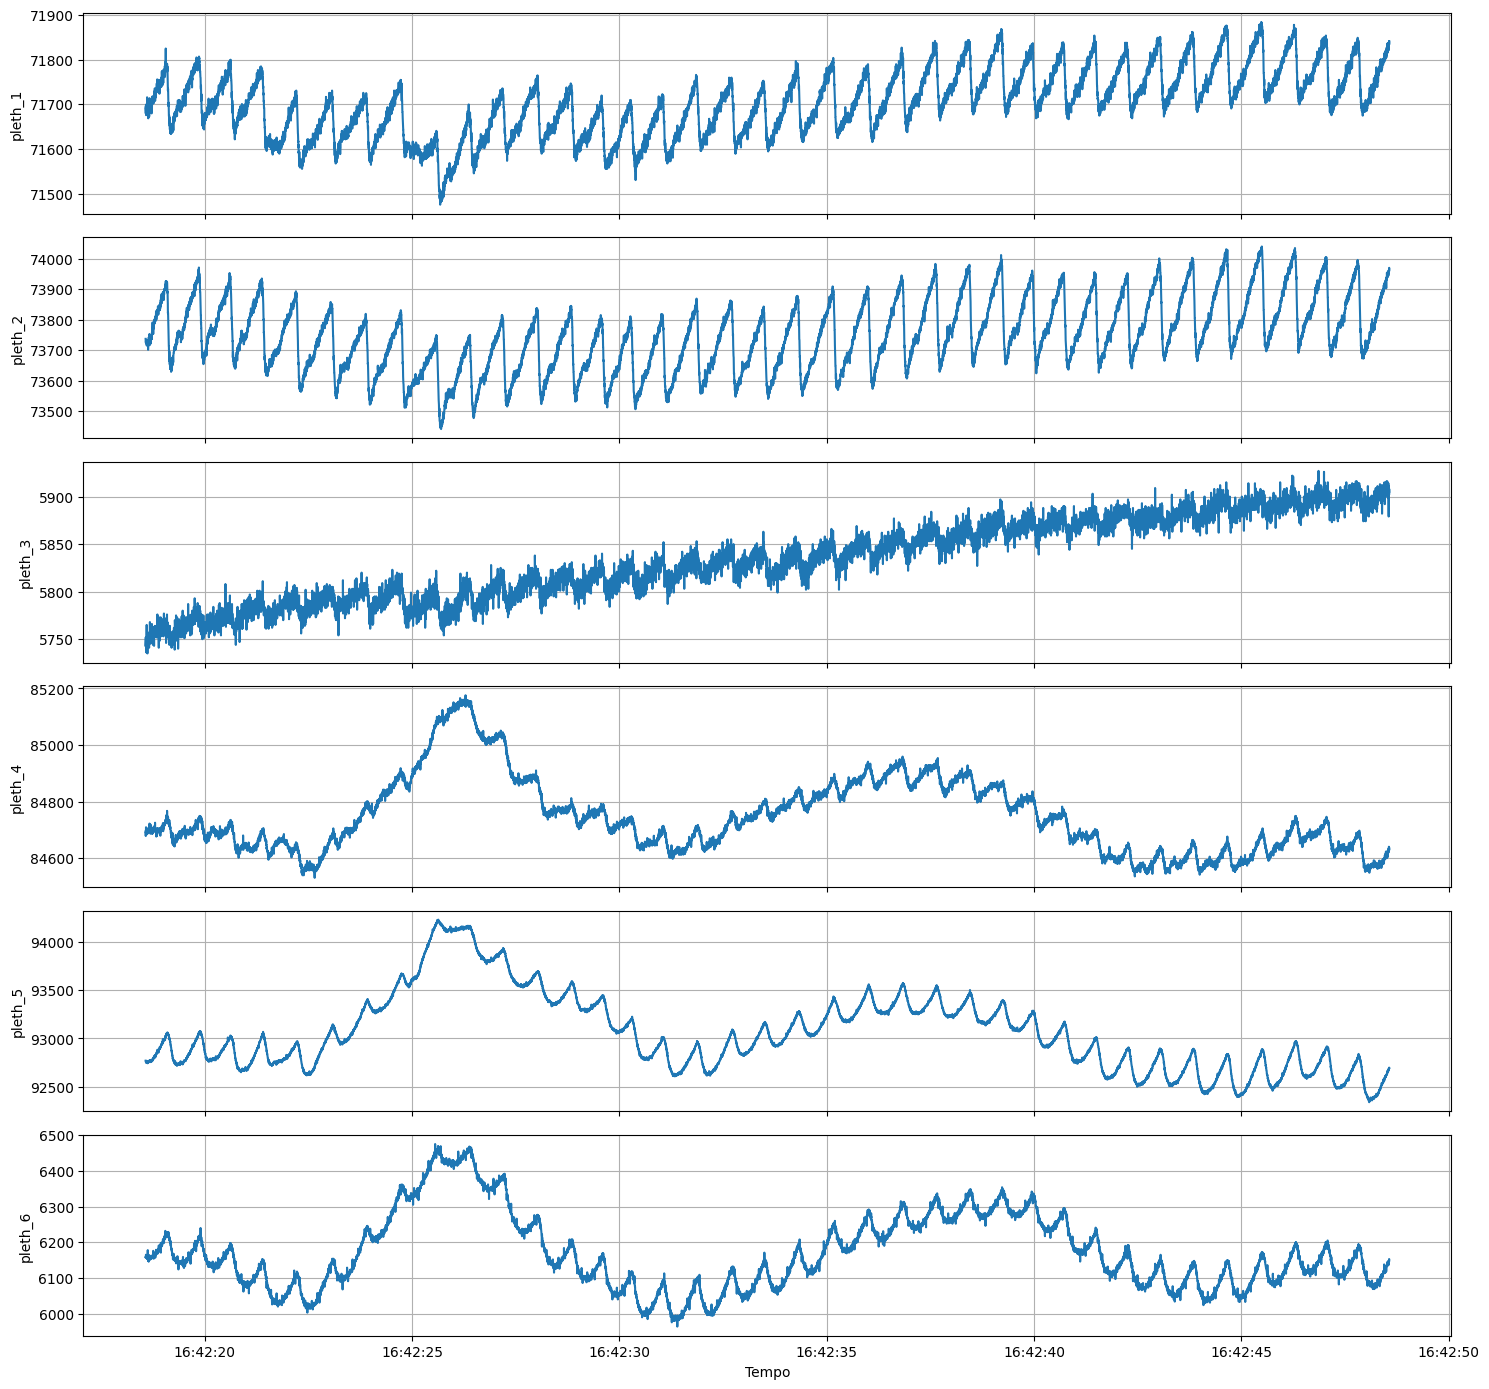

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

# Converter a coluna de tempo para data/hora
df["time"] = pd.to_datetime(df["time"])

# Mostrar somente os primeiros 30 segundos
inicio = df["time"].iloc[0]
fim = inicio + pd.Timedelta(seconds=30)

df_plot = df[(df["time"] >= inicio) & (df["time"] <= fim)]

ppg_channels = [
    "pleth_1",
    "pleth_2",
    "pleth_3",
    "pleth_4",
    "pleth_5",
    "pleth_6"
]

fig, axes = plt.subplots(6, 1, figsize=(15, 14), sharex=True)

for ax, channel in zip(axes, ppg_channels):
    ax.plot(df_plot["time"], df_plot[channel])
    ax.set_ylabel(channel)
    ax.grid(True)

axes[-1].set_xlabel("Tempo")
plt.tight_layout()
plt.show()

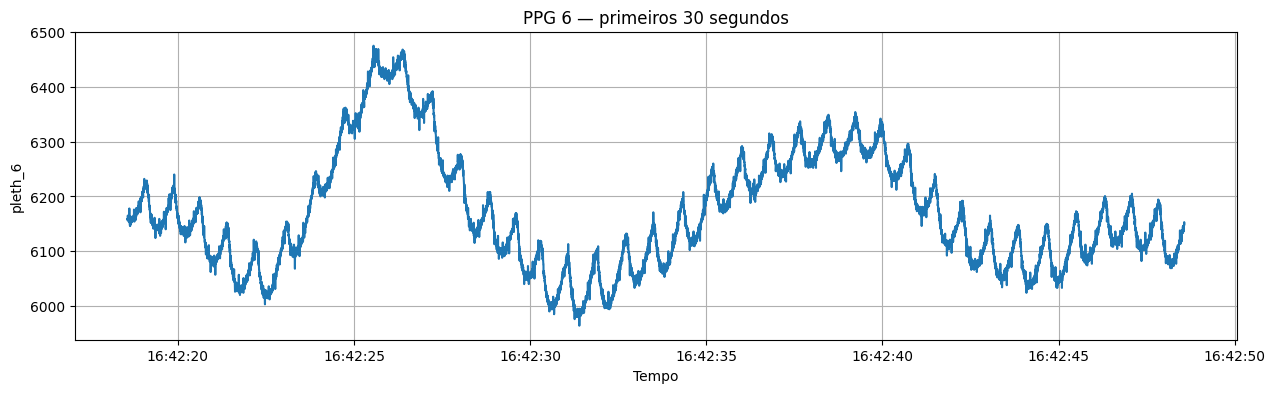

In [5]:
plt.figure(figsize=(15, 4))

plt.plot(df_plot["time"], df_plot["pleth_6"])

plt.xlabel("Tempo")
plt.ylabel("pleth_6")
plt.title("PPG 6 — primeiros 30 segundos")
plt.grid(True)

plt.show()

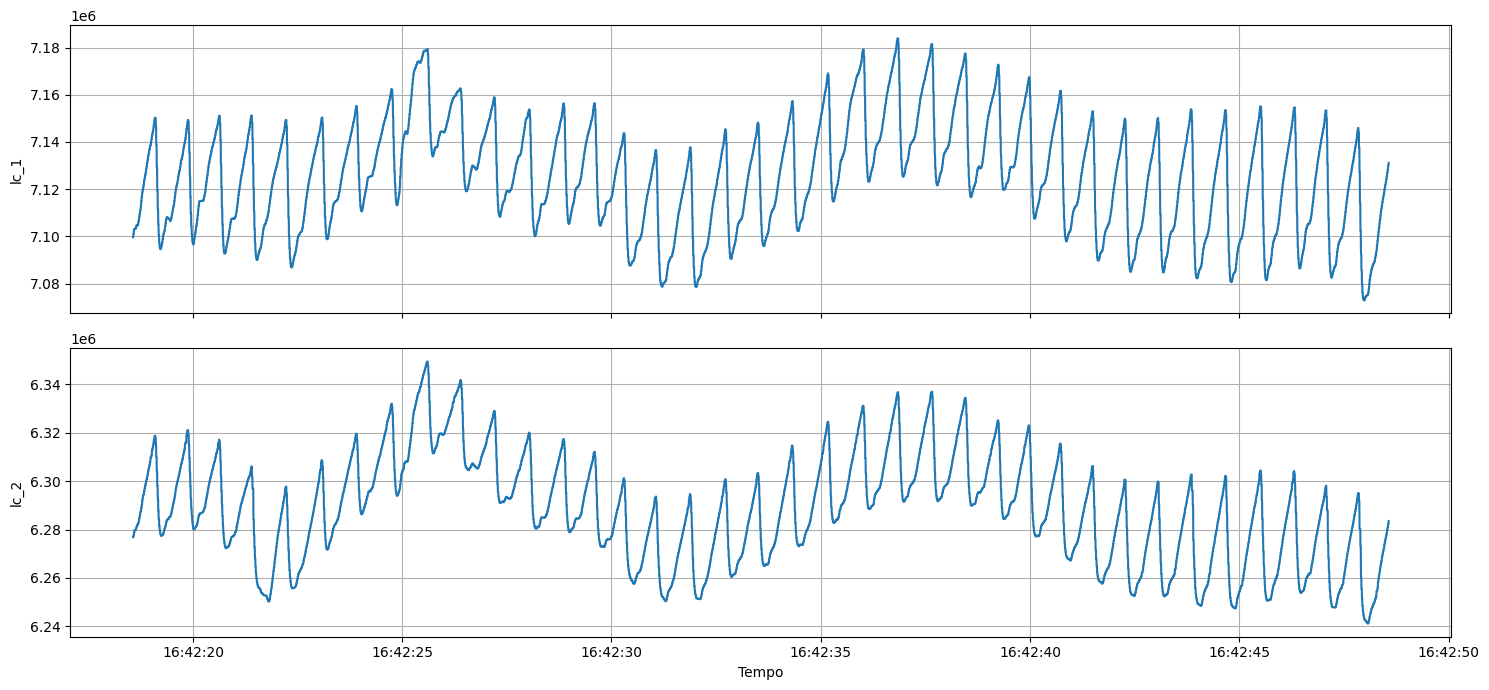

In [6]:
import matplotlib.pyplot as plt

pressure_channels = ["lc_1", "lc_2"]

fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True)

for ax, channel in zip(axes, pressure_channels):
    ax.plot(df_plot["time"], df_plot[channel])
    ax.set_ylabel(channel)
    ax.grid(True)

axes[-1].set_xlabel("Tempo")
plt.tight_layout()
plt.show()

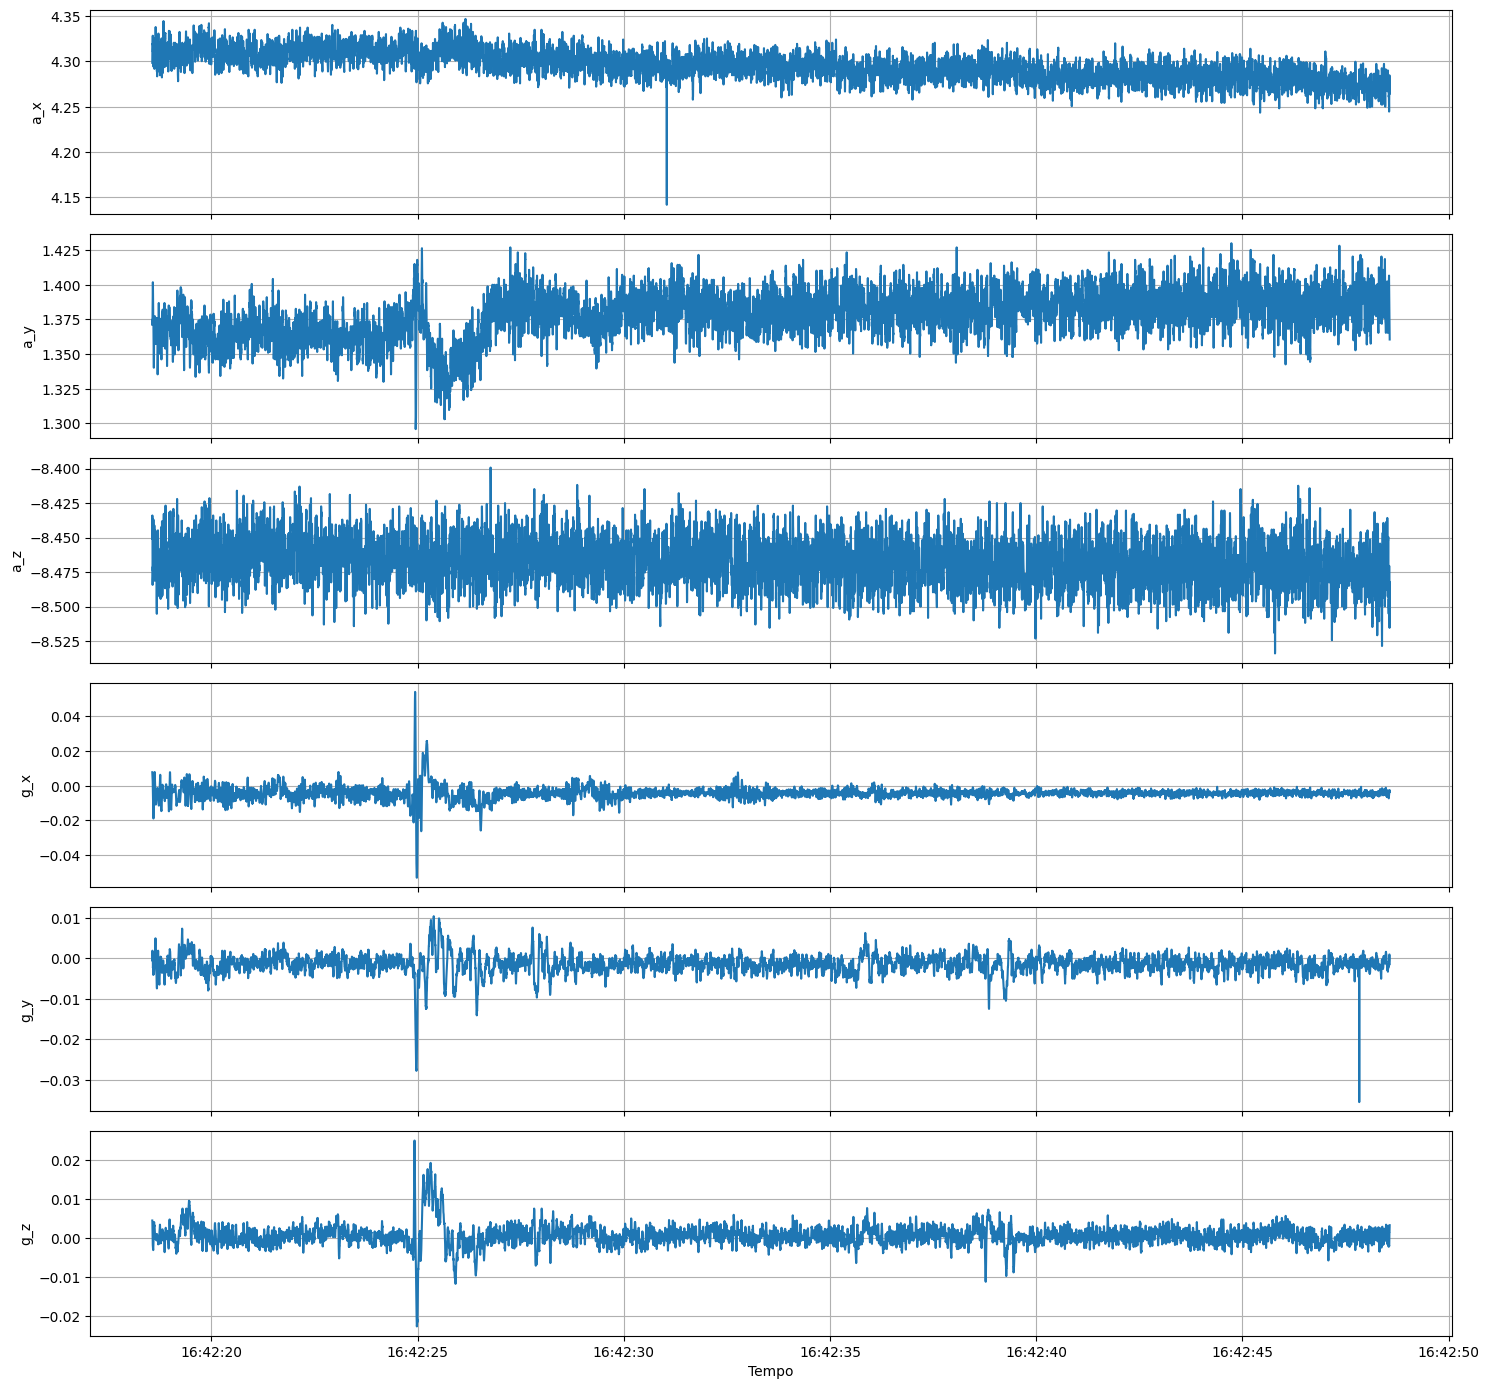

In [7]:
motion_channels = [
    "a_x", "a_y", "a_z",
    "g_x", "g_y", "g_z"
]

fig, axes = plt.subplots(6, 1, figsize=(15, 14), sharex=True)

for ax, channel in zip(axes, motion_channels):
    ax.plot(df_plot["time"], df_plot[channel])
    ax.set_ylabel(channel)
    ax.grid(True)

axes[-1].set_xlabel("Tempo")
plt.tight_layout()
plt.show()

## Auditoria inicial — s1_sit

**PPGs:**  
Os seis canais PPG foram visualizados durante os primeiros 30 segundos do registro. Os canais apresentaram comportamentos diferentes entre si. Neste trecho, `pleth_1` e `pleth_2` apresentaram pulsação mais evidente e regular, enquanto os demais canais apresentaram maior variação lenta e/ou ruído visual. Essa observação é apenas inicial e não será utilizada, isoladamente, para selecionar o canal PPG definitivo.

**Pressão de contato:**  
Os canais `lc_1` e `lc_2` foram analisados visualmente para observar sua estabilidade e suas variações ao longo do registro. Essas informações serão utilizadas posteriormente na extração de características de pressão e na avaliação de sua contribuição para a previsão do erro da estimativa de HR por PPG.

**Movimento:**  
Os sinais do acelerômetro (`a_x`, `a_y`, `a_z`) e do giroscópio (`g_x`, `g_y`, `g_z`) foram visualizados para identificar variações e possíveis períodos de movimento. Essas informações serão posteriormente transformadas em características de movimento para avaliar se acrescentam informação além dos SQIs do PPG.

**Observação:**  
Esta análise corresponde apenas à auditoria inicial do registro `s1_sit`. A seleção do canal PPG e as demais decisões do projeto deverão ser realizadas posteriormente de forma reprodutível e sem utilizar informações dos sujeitos de teste.